# Week 2 — Data-analytic thinking in Python
**AI in Business · MSc Business Analytics and AI**

| Part | Topic | Business question |
|---|---|---|
| A | NumPy: the dot product as a **weighted score** | How do we rank 1,000 customers with one line of code? |
| B | pandas + Matplotlib on a real churn dataset | Which 200 customers should we call this week? |

Reading for this week: Provost & Fawcett, *Data Science for Business*, chapters 1–2.

Cells marked **Exercise** are for you to complete, some in class and the rest is homework

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# We will work with pandas 3+ (the latest and coolest)
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.5.4 | pandas 3.0.6


In [3]:
# same "random" numbers for everyone
rng = np.random.default_rng(42)

# We can set some plotting parameters too
plt.rcParams.update({"figure.figsize": (7, 4), 
                     "axes.spines.top": False,
                     "axes.spines.right": False, 
                     "axes.grid": True,
                     "grid.alpha": 0.3})
# Set colors too: stayed / churned, used in every plot
BLUE, ORANGE = "#2a78d6", "#eb6834"

# NumPy: The workhorse behind numerical analysis and ML in python

## A1. Why arrays? Doing the same thing to many numbers at once

A Python list is a container. A NumPy **array** is a column of numbers you can do arithmetic on directly.

In [4]:
prices_list = [10, 20, 30]
prices_list

[10, 20, 30]

In [5]:
# a list repeats itself
print(prices_list * 2)    

[10, 20, 30, 10, 20, 30]


In [6]:
# To multiply every number bu a scalar you need
[i * 2 for i in prices_list]

[20, 40, 60]

In [7]:
# Numpy and its vectorized actions
prices = np.array([10, 20, 30])
prices

array([10, 20, 30])

In [8]:
# an array multiplies every element
print(prices * 2)
# Add 20% VAT to every price
print(prices * 1.2)

[20 40 60]
[12. 24. 36.]


In [9]:
# Lets geenrate a numpy array with 1M prices
big = rng.uniform(0, 100, size=1_000_000)

# Now lets measure the time it takes a list to multiply each item by the VAT
t0 = time.perf_counter()
with_vat_loop = [p * 1.2 for p in big]
t1 = time.perf_counter()

# Lets do the same with numpy
with_vat_np = big * 1.2
t2 = time.perf_counter()

# Now we print the output
print(f"Python loop: {t1 - t0:.3f}s")
print(f"NumPy: {t2 - t1:.4f}s (about {(t1 - t0) / (t2 - t1):.0f}x faster)")

Python loop: 0.160s
NumPy: 0.0020s (about 82x faster)


## A2. The dot product is a weighted score

A marketing team ranks sales leads with a simple rule:

> **score = 2 × (website visits) + 1 × (emails opened) + 0.5 × (years as customer)**

Each customer is a list of numbers (a **vector**). The rule is another vector, the **weights**.

| Customer | Visits | Emails opened | Years |
|---|---|---|---|
| Arta | 5 | 3 | 2 |
| Besnik | 1 | 8 | 10 |
| Drita | 7 | 0 | 1 |

For Arta: 2·5 + 1·3 + 0.5·2 = 10 + 3 + 1 = **14**.

Multiply matching entries, then add them up. That is all a **dot product** is:

$$ \mathbf{w}\cdot\mathbf{x} \;=\; w_1x_1 + w_2x_2 + \dots + w_nx_n \;=\; \sum_{i=1}^{n} w_i x_i $$

### Exercise 1
On paper, compute the scores of Besnik and Drita. I know this is boring, but understanding math is essential in analytics

In [11]:
# Lets define a vector of weights: 3 features, thus vector length is 3
w = np.array([2, 1, 0.5])

# Pick Arta as an example
arta = np.array([5, 3, 2])

# print("Arta by hand :", 2*5 + 1*3 + 0.5*2)
print("Arta, np.dot :", np.dot(w, arta))
# @ is the dot-product operator
print("Arta, w @ x  :", w @ arta)

# Your turn: create besnik and drita and print their scores
## Solutions
besnik = np.array([1, 8, 10])
drita = np.array([7, 0, 1])
print("Besnik:", w @ besnik)
print("Drita :", w @ drita)

Arta, np.dot : 14.0
Arta, w @ x  : 14.0
Besnik: 15.0
Drita : 14.5


**Weights can be negative.** 

Add a fourth feature, *number of complaints*, with weight −3. A complaint now *lowers* the score.

Discuss: who decides these weights? (Next weeks: we let the data decide. As you may recall from foundations of ML or Statistics with Python courses, A linear or logistic regression *is* a dot product whose weights are learned.)

In [12]:
w4 = np.array([2, 1, 0.5, -3])
# Arta complained twice
arta4 = np.array([5, 3, 2, 2])
print("Arta with complaints:", w4 @ arta4)

Arta with complaints: 8.0


## A3. Scoring everyone at once: matrix × vector

Stack the customers as rows of a table (a **matrix** `X`). Then `X @ w` takes the dot product of **every row** with `w`: one score per customer.

In [13]:
X = np.array([[5, 3, 2],     # Arta
              [1, 8, 10],    # Besnik
              [7, 0, 1]])    # Drita
names = np.array(["Arta", "Besnik", "Drita"])

scores = X @ w
print(scores)
print("Ranking, best first:", names[np.argsort(-scores)])

[14.  15.  14.5]
Ranking, best first: ['Besnik' 'Drita' 'Arta']


### Simulated Scnario

Simulations are my favorites, and computers allow you to simulate anything!

Now a realistic size: **1,000 customers** (simulated data).

In [14]:
# Let's soft code (remember python)
n = 1000
# website visits last month
visits = rng.poisson(4, n)
# emails opened
emails = rng.poisson(3, n)
# years as customer
years = rng.integers(0, 15, n)
# monthly income, EUR
income = rng.normal(900, 300, n).clip(300)

X_big = np.column_stack([visits, emails, years])
print("X_big has shape", X_big.shape, "(rows = customers, columns = features)")
print(X_big[:5])

X_big has shape (1000, 3) (rows = customers, columns = features)
[[ 2  7  1]
 [ 6  2  3]
 [ 3  1 14]
 [ 9  6 10]
 [ 0  2  4]]


### Exercise 2
1. Compute `scores_big`: the score of all 1,000 customers with one line.
2. Print the indices of the 10 best customers (hint: `np.argsort`).
3. What share of customers have a score above 15? (hint: `(scores_big > 15).mean()`)

In [15]:
# Solution
scores_big = X_big @ w
top10 = np.argsort(-scores_big)[:10]
print("Top 10 customers:", top10)
print("Their scores:   ", scores_big[top10])
print(f"Share with score > 15: {(scores_big > 15).mean():.1%}")

Top 10 customers: [583 439 612   3  10 898 120 140 405  55]
Their scores:    [33.5 29.5 29.  29.  28.5 28.  28.  28.  28.  27.5]
Share with score > 15: 45.1%


## A4. The units problem: why we standardize

Add **income (EUR)** to the score with a small weight of 0.05. Income is in the hundreds, the other features are single digits, so the column with the biggest numbers quietly takes over the ranking.

The fix is to put every feature on the same scale with a **z-score**:

$$ z = \frac{x - \text{mean}}{\text{standard deviation}} $$

A z-score of +1 means "one standard deviation above the average customer", whatever the original unit.

In [23]:
X_inc = np.column_stack([visits, emails, years, income])

# We change the weight vector
w_inc = np.array([2, 1, 0.5, 0.05])

# Have a look only at the first 3 columns of the array
print(X_inc[:3])
print("-" * 50)
# Now print the mean and standard deviation of each column 
print("Column means:", X_inc.mean(axis=0).round(1))
print("Column std  :", X_inc.std(axis=0).round(1))

[[2.00000000e+00 7.00000000e+00 1.00000000e+00 3.00000000e+02]
 [6.00000000e+00 2.00000000e+00 3.00000000e+00 1.02788526e+03]
 [3.00000000e+00 1.00000000e+00 1.40000000e+01 1.32297953e+03]]
--------------------------------------------------
Column means: [  4.1   3.    7.1 902.3]
Column std  : [  1.9   1.7   4.3 290.9]


In [24]:
raw_scores = X_inc @ w_inc
contrib = X_inc * w_inc
print("Average contribution of each feature:", contrib.mean(axis=0).round(1))

Average contribution of each feature: [ 8.3  3.   3.5 45.1]


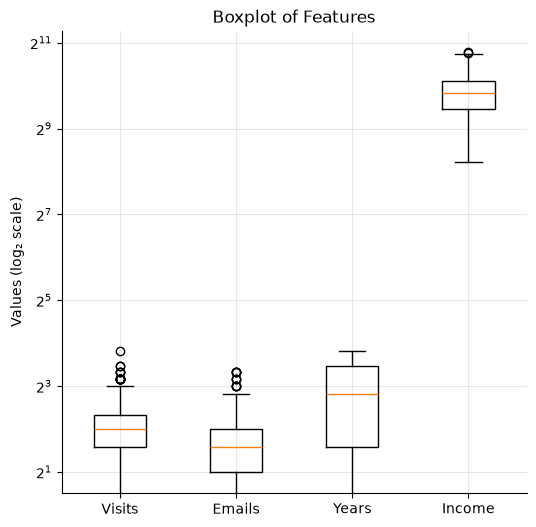

In [26]:
# Lets create boxplot and see whats going on
plt.figure(figsize=(6, 6))
plt.boxplot(X_inc, tick_labels=['Visits', 'Emails', 'Years', 'Income'])
plt.yscale('log', base=2)
plt.ylabel('Values (log₂ scale)')
plt.title('Boxplot of Features')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [27]:
# Now Standardize: We can write the formula above as such
# Remember we are standardizing each column
Z = (X_inc - X_inc.mean(axis=0)) / X_inc.std(axis=0)
print("Means:", Z.mean(axis=0).round(3))
print("Stds :", Z.std(axis=0).round(3))

Means: [-0.  0. -0. -0.]
Stds : [1. 1. 1. 1.]


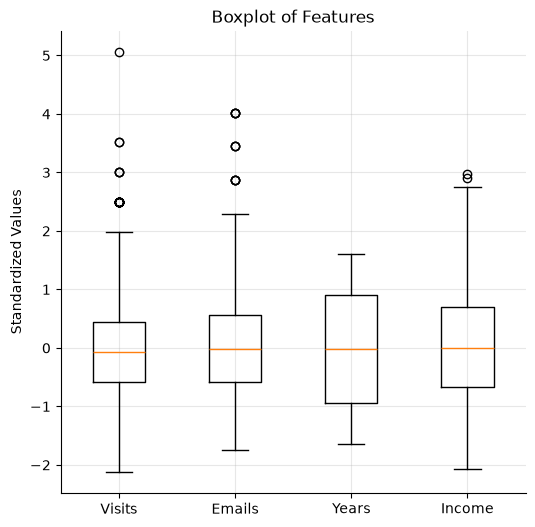

In [30]:
# Lets create boxplot and see what changed after normalization
plt.figure(figsize=(6, 6))
plt.boxplot(Z, tick_labels=['Visits', 'Emails', 'Years', 'Income'])
# plt.yscale('log', base=2)
plt.ylabel('Standardized Values')
plt.title('Boxplot of Features')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [36]:
z_scores = Z @ np.array([2, 1, 0.5, 1])
top_raw = set(np.argsort(-raw_scores)[:100])
top_std = set(np.argsort(-z_scores)[:100])
print("Customers in both top-100 lists:", len(top_raw & top_std))

Customers in both top-100 lists: 36


## A5. Look at the scores

A histogram shows how scores are spread. The dashed line marks the cut-off for the top 10%.

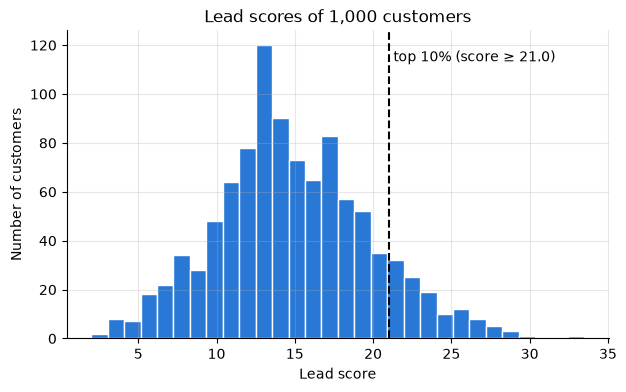

In [38]:
scores_big = X_big @ w

# This is very useful: You can pick any percentile you wish
cut = np.percentile(scores_big, 90)

# Plot it
fig, ax = plt.subplots()
ax.hist(scores_big, bins=30, color=BLUE, edgecolor="white")
ax.axvline(cut, color="black", linestyle="--", linewidth=1.5)
ax.text(cut + 0.3, ax.get_ylim()[1] * 0.9, f"top 10% (score ≥ {cut:.1f})")
ax.set_xlabel("Lead score")
ax.set_ylabel("Number of customers")
ax.set_title("Lead scores of 1,000 customers")
plt.show()

> **Take-away for Part A.** A score is a dot product. A model that scores customers (regression, logistic regression, the last layer of a neural network) computes `X @ w`. What changes from model to model is **how the weights are chosen**.

# Part B — pandas: a real churn problem

Provost & Fawcett's chapter 1 opens with *MegaTelCo*, a phone company losing customers. 

Here is a real version: the IBM **Telco Customer Churn** sample, about 7,000 customers of a telecom company. 

`Churn = Yes` means the customer left last month.

In [40]:
# Load the data (Either use your local file or download directly from github)
from pathlib import Path

LOCAL = Path("telco_churn.csv")
URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")

df = pd.read_csv(LOCAL if LOCAL.exists() else URL)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [41]:
print(df.shape)

(7043, 21)


In [42]:
# A quick inspection: Nothing is missing, but "TotalCharges" charges is not numeric as as expected
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## B2. Data quality: always check before you analyse

`TotalCharges` should be a number, but `info()` shows it is stored as text (`object` in pandas 2, `str` in pandas 3, so dont get confused).

In [43]:
# Let's convert TotalCharges to numeric
df["TotalCharges_num"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Find cases where conversion did not happen (It was NA already)
bad = df[df["TotalCharges_num"].isna()]

# Show the cases
print(len(bad), "rows could not be converted")
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

11 rows could not be converted


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


### Exercise 4
Look at the `tenure` of these rows. What do they have in common, and what is the most sensible value for their `TotalCharges`? Fix the column, then drop the helper column.

In [44]:
# All have tenure = 0: brand-new customers who have not been billed yet, so no charges -> NA, lets make it 0
# Pandas will replace all NAs by 0
df["TotalCharges"] = df["TotalCharges_num"].fillna(0)
df = df.drop(columns="TotalCharges_num")

# Always check
print(df["TotalCharges"].dtype, "| missing:", df["TotalCharges"].isna().sum())

float64 | missing: 0


## B3. The target: how many customers leave?

In [45]:
# We can have a simple check
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [46]:
# Turn to probabilities
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [48]:
# Or turn them into integers (Yes = 1, No = 0)
df["churned"] = (df["Churn"] == "Yes").astype(int)
base_rate = df["churned"].mean()

print(f"Base churn rate: {base_rate:.1%}  ({df['churned'].sum():,} of {len(df):,} customers)")

Base churn rate: 26.5%  (1,869 of 7,043 customers)


In [50]:
# Now the data looks like this
df[["Churn", "churned"]].head()

,Churn,churned
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


## B4. Who churns? `groupby`

The mean of a 0/1 column is a rate, so `groupby(...)["churned"].mean()` gives the churn rate per group.

This is one of the most useful functions in pandas, its hard to do justice to its value

In [51]:
# Let's check the types of contracts
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [52]:
# I will group customers by contract type, calculate the numbers for each case and the mean churn (leaving)
# and also order them from highest to the lowest
by_contract = (df.groupby("Contract")["churned"]
                 .agg(customers="size", churn_rate="mean")
                 .sort_values("churn_rate", ascending=False))
by_contract.head()

,customers,churn_rate
Contract,,
Month-to-month,3875,0.427097
One year,1473,0.112695
Two year,1695,0.028319


In [53]:
# Remeber base rate (all churners in the entire dataset)
# We call this the Risk Ratio (RR)
by_contract["lift_vs_base"] = by_contract["churn_rate"] / base_rate
by_contract.round(3)

,customers,churn_rate,lift_vs_base
Contract,,,
Month-to-month,3875,0.427,1.609
One year,1473,0.113,0.425
Two year,1695,0.028,0.107


**Lift** = group churn rate ÷ base rate. A lift of 1.6 means "60% more likely to churn than the average customer".

In more detail:

**Month-to-month**: Customers have 1.61× the overall churn rate (60.9% higher).

**One year**: Customers have 0.425× the overall churn rate (57.5% lower).

**Two year**: Customers have 0.107× the overall churn rate (89.3% lower).

### Exercise 5
Make the same table for `PaymentMethod` and for `InternetService`. Which single group has the highest churn rate? Is it a big group or a small one?

In [54]:
# Split the for loop into two
for col in ["PaymentMethod", "InternetService"]:
    t = (df.groupby(col)["churned"]
           .agg(customers="size", churn_rate="mean")
           .sort_values("churn_rate", ascending=False))
    t["lift_vs_base"] = t["churn_rate"] / base_rate
    print(t.round(3), "\n")

                           customers  churn_rate  lift_vs_base
PaymentMethod                                                 
Electronic check                2365       0.453         1.707
Mailed check                    1612       0.191         0.720
Bank transfer (automatic)       1544       0.167         0.630
Credit card (automatic)         1522       0.152         0.574 

                 customers  churn_rate  lift_vs_base
InternetService                                     
Fiber optic           3096       0.419         1.579
DSL                   2421       0.190         0.714
No                    1526       0.074         0.279 



## B5. Plots that answer a question

**Plot 1: churn rate by contract type**, with the base rate for reference.

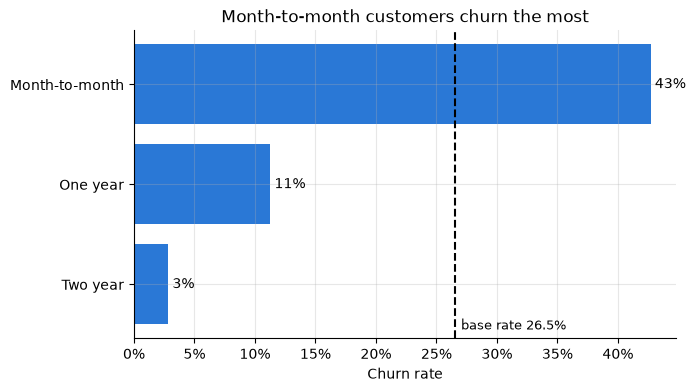

In [55]:
fig, ax = plt.subplots()
# Sort values: It's always good practice in visualization to easily see the patterns
rates = by_contract["churn_rate"].sort_values()

bars = ax.barh(rates.index, rates.values, color=BLUE)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in rates.values], padding=3)
ax.axvline(base_rate, color="black", linestyle="--", linewidth=1.5)
ax.text(base_rate + 0.005, -0.45, f"base rate {base_rate:.1%}", fontsize=9)
ax.set_xlabel("Churn rate")
ax.set_title("Month-to-month customers churn the most")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

**Plot 2: churn rate by tenure.** `pd.cut` turns months of tenure into bands.

In [59]:
# Lets see the tenure (How long we have had the customers)
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [60]:
bins = [0, 6, 12, 24, 48, 72]
labels = ["0–6", "7–12", "13–24", "25–48", "49–72"]

# Introduce a new column to the df where each customer is bucketed into one of the 6 bins
df["tenure_band"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)

# Calculate the mean churn for each band
by_tenure = df.groupby("tenure_band", observed=True)["churned"].mean()
by_tenure

tenure_band
0–6      0.529372
7–12     0.358865
13–24    0.287109
25–48    0.203890
49–72    0.095132
Name: churned, dtype: float64

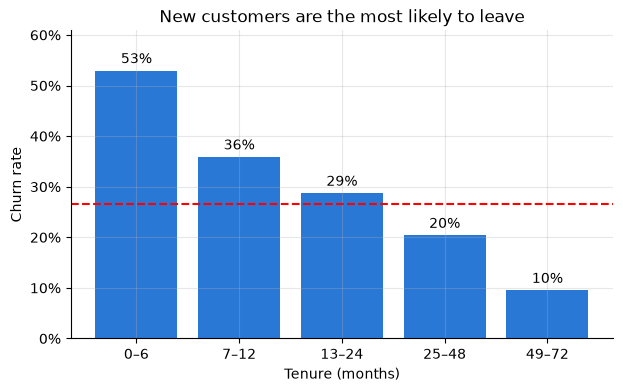

In [61]:
# Now plot it
fig, ax = plt.subplots()
bars = ax.bar(by_tenure.index.astype(str), by_tenure.values, color=BLUE)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in by_tenure.values], padding=3)
ax.axhline(base_rate, color="red", linestyle="--", linewidth=1.5)
ax.set_ylim(0, by_tenure.max() * 1.15)
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate")
ax.set_title("New customers are the most likely to leave")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

**Plot 3: monthly charges of customers who stayed vs. left.**

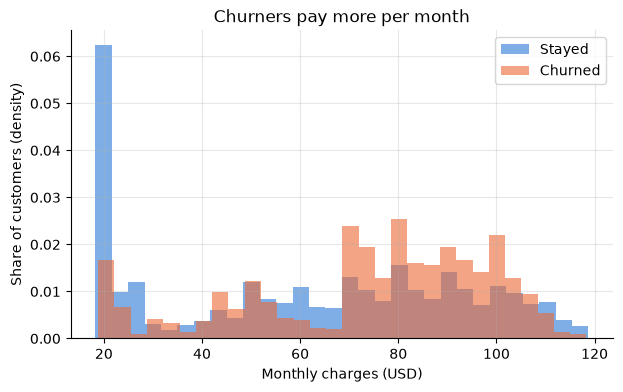

In [62]:
fig, ax = plt.subplots()
for label, color in [("No", BLUE), ("Yes", ORANGE)]:
    ax.hist(df.loc[df["Churn"] == label, "MonthlyCharges"], bins=30,
            alpha=0.6, color=color, density=True,
            label="Stayed" if label == "No" else "Churned")
ax.set_xlabel("Monthly charges (USD)")
ax.set_ylabel("Share of customers (density)")
ax.set_title("Churners pay more per month")
ax.legend()
plt.show()

**Plot 4: two variables at once.** A pivot table of churn rate by contract × internet service, shown as a heatmap.

In [64]:
# Another way to quickly summarize data
pivot = df.pivot_table(index="Contract", 
                       columns="InternetService",
                       values="churned", 
                       aggfunc="mean")
pivot

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,0.322159,0.546053,0.188931
One year,0.092982,0.192950,0.024725
Two year,0.019108,0.072261,0.007837


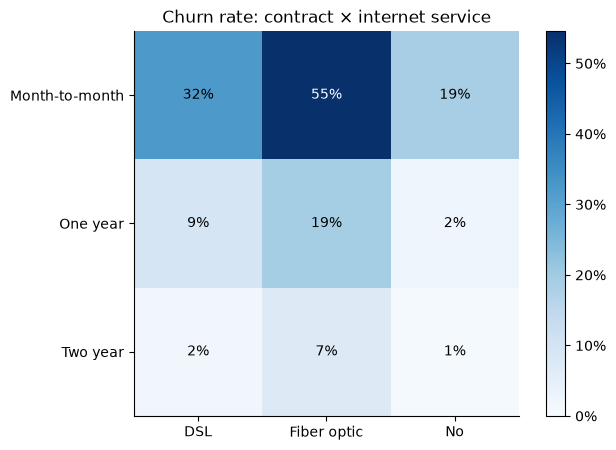

In [65]:
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pivot.values, cmap="Blues", vmin=0, vmax=pivot.values.max())
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.grid(False)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center",
                color="white" if v > pivot.values.max() * 0.6 else "black")
ax.set_title("Churn rate: contract × internet service")
plt.colorbar(im, ax=ax, format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

## B6. The challenge: you can call 200 customers this week

The retention team has time for **200 calls**. Build a **hand-made risk score** with what you learned in Part A, and pick the 200 highest scores.

1. Turn the risk factors you found into 0/1 columns (e.g. month-to-month contract, fiber optic, electronic check, tenure ≤ 12 months, senior citizen).
2. Choose a weight for each one.
3. Score every customer with `F @ weights`, take the top 200, and compute their churn rate and **lift**.
4. Compare with 200 customers picked at random.

Report your lift to the class. Highest lift wins.

### Exercise 6

In [72]:
# Lets quickly see what we got
my_features = ["Contract", "InternetService", "PaymentMethod", "tenure", "SeniorCitizen", "TechSupport"]

for i in my_features:
    print(df[i].value_counts())
    print("-" *50)

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64
--------------------------------------------------
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
--------------------------------------------------
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64
--------------------------------------------------
tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64
--------------------------------------------------
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
--------------------------------------------------
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64
--------------------------

In [74]:
# Solution

# 1 - Create a dataframe with all the conditions mentioned above (binarize)
F = pd.DataFrame({
    # Month-to-month is 1, the rest 0
    "month_to_month": (df["Contract"] == "Month-to-month").astype(int),
    # fiber-optic is 1, the rest 0
    "fiber": (df["InternetService"] == "Fiber optic").astype(int),
    # check payers 1, the rest 0
    "e_check": (df["PaymentMethod"] == "Electronic check").astype(int),
    # anyone with less than 12 months tenure is 1, the rest 0
    "new_customer":(df["tenure"] <= 12).astype(int),
    # SeniorCitizen is already 1/0
    "senior": df["SeniorCitizen"],
    # no tech support -> 1
    "no_tech_support": (df["TechSupport"] == "No").astype(int),
})

F.head()

,month_to_month,fiber,e_check,new_customer,senior,no_tech_support
0,1,0,1,1,0,1
1,0,0,0,0,0,1
2,1,0,0,1,0,1
3,0,0,0,0,0,0
4,1,1,1,1,0,1


In [76]:
# We need a vector of 6 weights (6 columns, recall dot product)
weights = np.array([3, 2, 2, 2, 1, 1])
risk = F.to_numpy() @ weights

# Show the first 20 rows
risk[:20]

array([ 8,  1,  6,  0, 10, 10,  6,  6,  7,  1,  4,  0,  3,  6,  7,  2,  0,
        3,  5,  8])

In [78]:
# Sort from highest to lowest, pick first 200 hundred
top200 = np.argsort(-risk, kind="stable")[:200]

# Pick the same customers from the table
rate_top = df["churned"].iloc[top200]

rate_top

238    1
245    0
288    1
293    0
301    1
      ..
474    1
484    1
489    1
492    1
532    0
Name: churned, Length: 200, dtype: int64

In [80]:
# Calculate their mean
rate_top = df["churned"].iloc[top200].mean()

# Pick randomly 200 customers and calculate their mean
random200 = rng.choice(len(df), size=200, replace=False)
rate_rand = df["churned"].iloc[random200].mean()

print(f"Top-200 by risk score: churn rate {rate_top:.0%}, lift {rate_top / base_rate:.2f}")
print(f"Random 200:            churn rate {rate_rand:.0%}, lift {rate_rand / base_rate:.2f}")

Top-200 by risk score: churn rate 74%, lift 2.81
Random 200:            churn rate 27%, lift 1.02


### Discussion (5 minutes)
- Your top 200 churn far more than average. **Is calling them the right decision?** What does a call cost, and what is a retained customer worth?
- Some of them will leave whatever you do; some would have stayed anyway. A churn score says **who will leave**, not **whose mind a call can change**. (Remember the "persuadables" and "sleeping dogs" from week 1.)
- Next week: Provost & Fawcett ch. 7–8. We turn this into an **expected-value** decision and choose how many to call by profit, not by gut feeling.

---
# Exit ticket (5 minutes, on paper)

**Q1.** Compute the dot product of **w** = (2, −1, 3) and **x** = (4, 5, 1).

**Q2.** A supermarket asks: *"Which products do customers buy together?"* Which type of data-mining task is this (Provost & Fawcett ch. 2), and is it supervised or unsupervised?

**Q3.** A bank's churn table:

| Card type | Customers | Churn rate |
|---|---|---|
| Basic | 6,000 | 12% |
| Gold | 3,000 | 6% |
| Student | 1,000 | 30% |

(a) What is the bank's overall churn rate? (b) What is the lift of the Student group? (c) Which group loses the **most customers** in absolute numbers?